

# Science Fair 2023 - 2024

# Smart Diagnostics COVID Detection using AI

# By: Reyansh Gupta

## Problem Statement:

Covid tests like the rt-pcr test can be time consuming and can be resource intensive. This can result in long wait times in covid detection. To solve the problem, I will build an AI(Artificial Intelligence) system to predict if a patient has Covid by identifying patterns in chest x-ray pictures.

## Solution Approach:

To do this, I will

* Learn the specific parts of code needed
* Aquire and Load the dataset(x-ray images)
* Train the model
* Analyze the model's performance
* Tune the model for higher performance
* Deploy the model for general use

## Importing all libraries

In [ ]:
# importing libraries
from IPython import display                                             
import numpy as np                                                      
import pandas as pd                                                    
import tensorflow as tf                                                
import os                                                               
import math   
                                                          

#Libraries to plot data
import matplotlib.pyplot as plt                                         
import seaborn as sns                                                   
from tensorflow.keras.preprocessing.image import ImageDataGenerator   
import cv2                                                              
from PIL import ImageFilter                                             

#Model building
from tensorflow.keras.layers.experimental import preprocessing         
from sklearn.metrics import recall_score, confusion_matrix              

#Model deployment
import joblib                                                           
import gradio as gr                                                     


import random as python_random                                          
np.random.seed(42)                                                      
tf.random.set_seed(42)


## Loading the Dataset

In [ ]:
# defining the dimensions of the images
height, width = 224, 224
# how many images to load in one go
batch_size=64

def generate_data(DIR):
    datagen = ImageDataGenerator(rescale=1./255.)
    generator = datagen.flow_from_directory(
        DIR,
        batch_size=batch_size,
        shuffle=True,                                                          
        seed=42,
        class_mode='binary',
        target_size=(height, width),
        classes={'Normal': 0, 'Viral Pneumonia': 1,'Covid': 2}
    )
    return generator
# generating testing and training data
TRAINING_DIR = 'Data/train'
TESTING_DIR = 'Data/test'

train_data = generate_data(TRAINING_DIR)                                       
test_data = generate_data(TESTING_DIR)                                         

total_image = np.concatenate([train_data.labels,test_data.labels])             



Found 690 images belonging to 3 classes.
Found 300 images belonging to 3 classes.



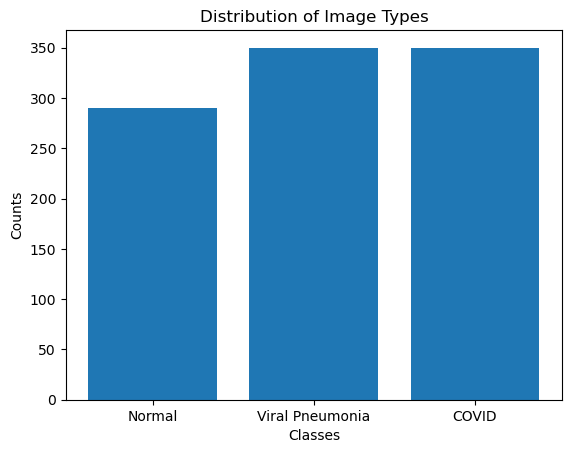

In [ ]:
# Calculating the count of COVID images
counts = {
    'Normal': len(np.where(total_image == 0)[0]),                              
    'Viral Pneumonia': len(np.where(total_image == 1)[0]),                     
    'COVID': len(np.where(total_image == 2)[0])                                
}


class_labels = list(counts.keys())
class_counts = list(counts.values())

# Create the bar plot
plt.bar(class_labels, class_counts)
plt.xlabel('Classes')
plt.ylabel('Counts')
plt.title('Distribution of Image Types')


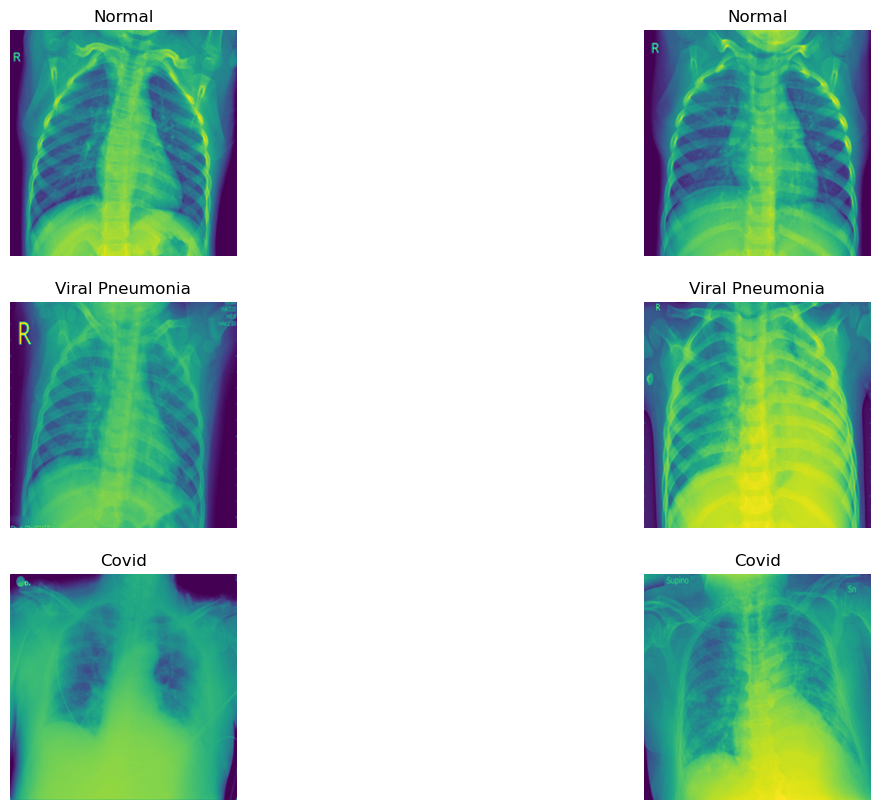

In [ ]:
def image_plot(generator, images_per_class):
    class_indices = generator.class_indices
    class_names = list(class_indices.keys())
    plt.figure(figsize=(15, 10))

    for class_idx, class_name in enumerate(class_names):
        class_indices = [i for i, value in enumerate(generator.classes) if value == class_idx]
        selected_indices = class_indices[:images_per_class]

        # Loop through the selected indices and display the images
        for i, idx in enumerate(selected_indices):
            # Create a subplot for each image
            ax = plt.subplot(len(class_names), images_per_class, class_idx * images_per_class + i + 1)
            # Load and display the image
            img = plt.imread(generator.filepaths[idx])
            plt.imshow(img)
            plt.title(class_name)
            plt.axis("off")

images_per_class = 2
image_plot(train_data, images_per_class)
plt.show()


## Building the Model

In [6]:
# defining the model
tf.keras.backend.clear_session()                                               

input_shape = (height, width, 3)                                               
base_model = tf.keras.applications.vgg16.VGG16(
    weights='imagenet',                                                        
    include_top=False,                                                         
    input_shape=input_shape
)
base_model.trainable = False                                                   
ai_model = tf.keras.Sequential()                                            
ai_model.add(base_model)                                                    
ai_model.add(tf.keras.layers.GlobalAveragePooling2D())                      

ai_model.add(tf.keras.layers.Flatten())                                     
ai_model.add(tf.keras.layers.Dense(3, activation='softmax'))               
ai_model.compile(loss='SparseCategoricalCrossentropy',                      
              optimizer=tf.keras.optimizers.Adam(0.001),                       
              metrics=['acc'])                                                 
ai_model.summary()



Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vgg16 (Functional)          (None, 7, 7, 512)         14714688  
                                                                 
 global_average_pooling2d (  (None, 512)               0         
 GlobalAveragePooling2D)                                         
                                                                 
 flatten (Flatten)           (None, 512)               0         
                                                                 
 dense (Dense)               (None, 3)                 1539      
                                                                 
Total params: 14716227 (56.14 MB)
Trainable params: 1539 (6.01 KB)
Non-trainable params: 14714688 (56.13 MB)
_________________________________________________________________



## Training the Model

In [7]:
checkpoint = tf.keras.callbacks.ModelCheckpoint('model/ai_model_best.h5', monitor='acc', verbose=1, mode='max',save_best_only=True) 
early = tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min",restore_best_weights=True, patience=5)  #stops the model training if there is no improvement in metrics 

callbacks_list = [checkpoint,early]

# Training the model
history = ai_model.fit(                                                     
        train_data,                                                            
        validation_data = test_data,                                           
        epochs=25,                                                             
        shuffle=False,
        verbose=True,                                                          
        callbacks=callbacks_list
)



Epoch 1/25
11/11 [==============================] - ETA: 0s - loss: 1.2178 - acc: 0.2754 
Epoch 1: acc improved from -inf to 0.27536, saving model to model\ai_model_best.h5




C:\Users\taman\anaconda3\lib\site-packages\keras\src\engine\training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(




11/11 [==============================] - 215s 20s/step - loss: 1.2178 - acc: 0.2754 - val_loss: 1.1085 - val_acc: 0.2967
Epoch 2/25
11/11 [==============================] - ETA: 0s - loss: 1.0901 - acc: 0.4420 
Epoch 2: acc improved from 0.27536 to 0.44203, saving model to model\ai_model_best.h5
11/11 [==============================] - 218s 20s/step - loss: 1.0901 - acc: 0.4420 - val_loss: 1.1022 - val_acc: 0.3933
Epoch 3/25
11/11 [==============================] - ETA: 0s - loss: 1.0498 - acc: 0.5072 
Epoch 3: acc improved from 0.44203 to 0.50725, saving model to model\ai_model_best.h5
11/11 [==============================] - 224s 21s/step - loss: 1.0498 - acc: 0.5072 - val_loss: 1.0330 - val_acc: 0.4667
Epoch 4/25
11/11 [==============================] - ETA: 0s - loss: 1.0002 - acc: 0.6000 
Epoch 4: acc improved from 0.50725 to 0.60000, saving model to model\ai_model_best.h5
11/11 [==============================] - 246s 23s/step - loss: 1.0002 - acc: 0.6000 - val_loss: 0.9725 - val

## Evaluating the Model

In [8]:
#model accuracy
ytrain = np.array([])                                                          
xtrain = []                                                                    

for i in range(math.ceil(len(train_data.classes)/batch_size)):                 
    xtrain.append(train_data[i][0])                                            
    ytrain= np.concatenate((ytrain,train_data[i][-1]))                         

xtrain = np.concatenate((xtrain),axis=0)                                       

ypred_prob_train =ai_model.predict(xtrain)                                 
ypred_train = np.argmax(ypred_prob_train,axis=1)                               



22/22 [==============================] - 111s 5s/step



In [9]:
model_train_score = recall_score(ytrain, ypred_train, average='macro')
print("Model Score on Train Data:", np.round(100*model_train_score, 2))



Model Score on Train Data: 90.44



## Training Accuraccy


[Text(45.72222222222221, 0.5, 'True label')]


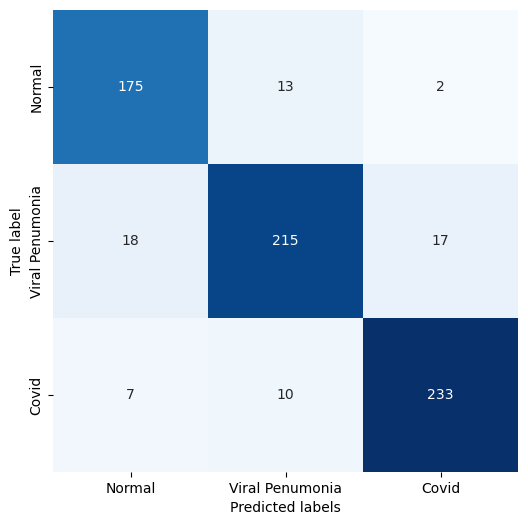

In [10]:
plt.figure(figsize=(6, 6))
hm = sns.heatmap(confusion_matrix(ytrain,ypred_train), annot=True, vmin=0, fmt='g', cmap='Blues', cbar=False,xticklabels=['Normal','Viral Penumonia','Covid'],yticklabels=['Normal','Viral Penumonia','Covid'])
hm.set(xlabel='Predicted labels') 
hm.set(ylabel='True label')


## Tesitng Accuraccy

In [11]:
#model accuracy
ytest = np.array([])                                                           
xtest = []                                                                     

for i in range(math.ceil(len(test_data.classes)/batch_size)):                  
    xtest.append(test_data[i][0])                                              
    ytest= np.concatenate((ytest,test_data[i][-1]))                            

xtest = np.concatenate((xtest),axis=0)                                         

ypred_prob_test =ai_model.predict(xtest)                                    
ypred_test = np.argmax(ypred_prob_test,axis=1)                       



10/10 [==============================] - 38s 4s/step



In [12]:
model_test_score = recall_score(ytest, ypred_test, average='macro')
print("Model Score on Test Data:", np.round(100*model_test_score, 2))



Model Score on Test Data: 90.33



## Testing model


[Text(45.72222222222221, 0.5, 'True label')]


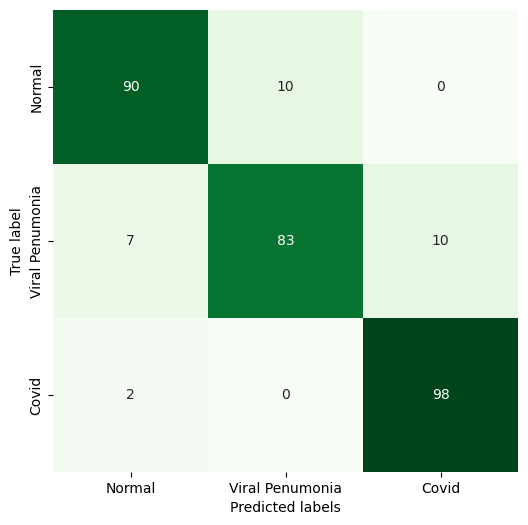

In [13]:
plt.figure(figsize=(6, 6))
hm = sns.heatmap(confusion_matrix(ytest, ypred_test), annot=True, vmin=0, fmt='g', cmap='Greens', cbar=False,xticklabels=['Normal','Viral Penumonia','Covid'],yticklabels=['Normal','Viral Penumonia','Covid'])
hm.set(xlabel='Predicted labels')
hm.set(ylabel='True label') 


### The Test Data shows that the computer struggles to tell the differrence between Viral Pneunomia and Covid compared to the other categories.

# Tuning the Model To Make it Better

## Creating More Images

In [14]:
def image_plot(generator, image_numbers):
    img_feature = generator[0][0][:image_numbers]
    img_label = generator[0][1][:image_numbers]

    plt.figure(figsize=(20, 15))
    for i in range(image_numbers):
        ax = plt.subplot(2, 3, i + 1) 
        plt.imshow(img_feature[i])
        plt.title("Normal" if img_label[i] == 0 else "Viral Pneumonia" if img_label[i] == 1 else "Covid")
        plt.axis("off")



Found 690 images belonging to 3 classes.



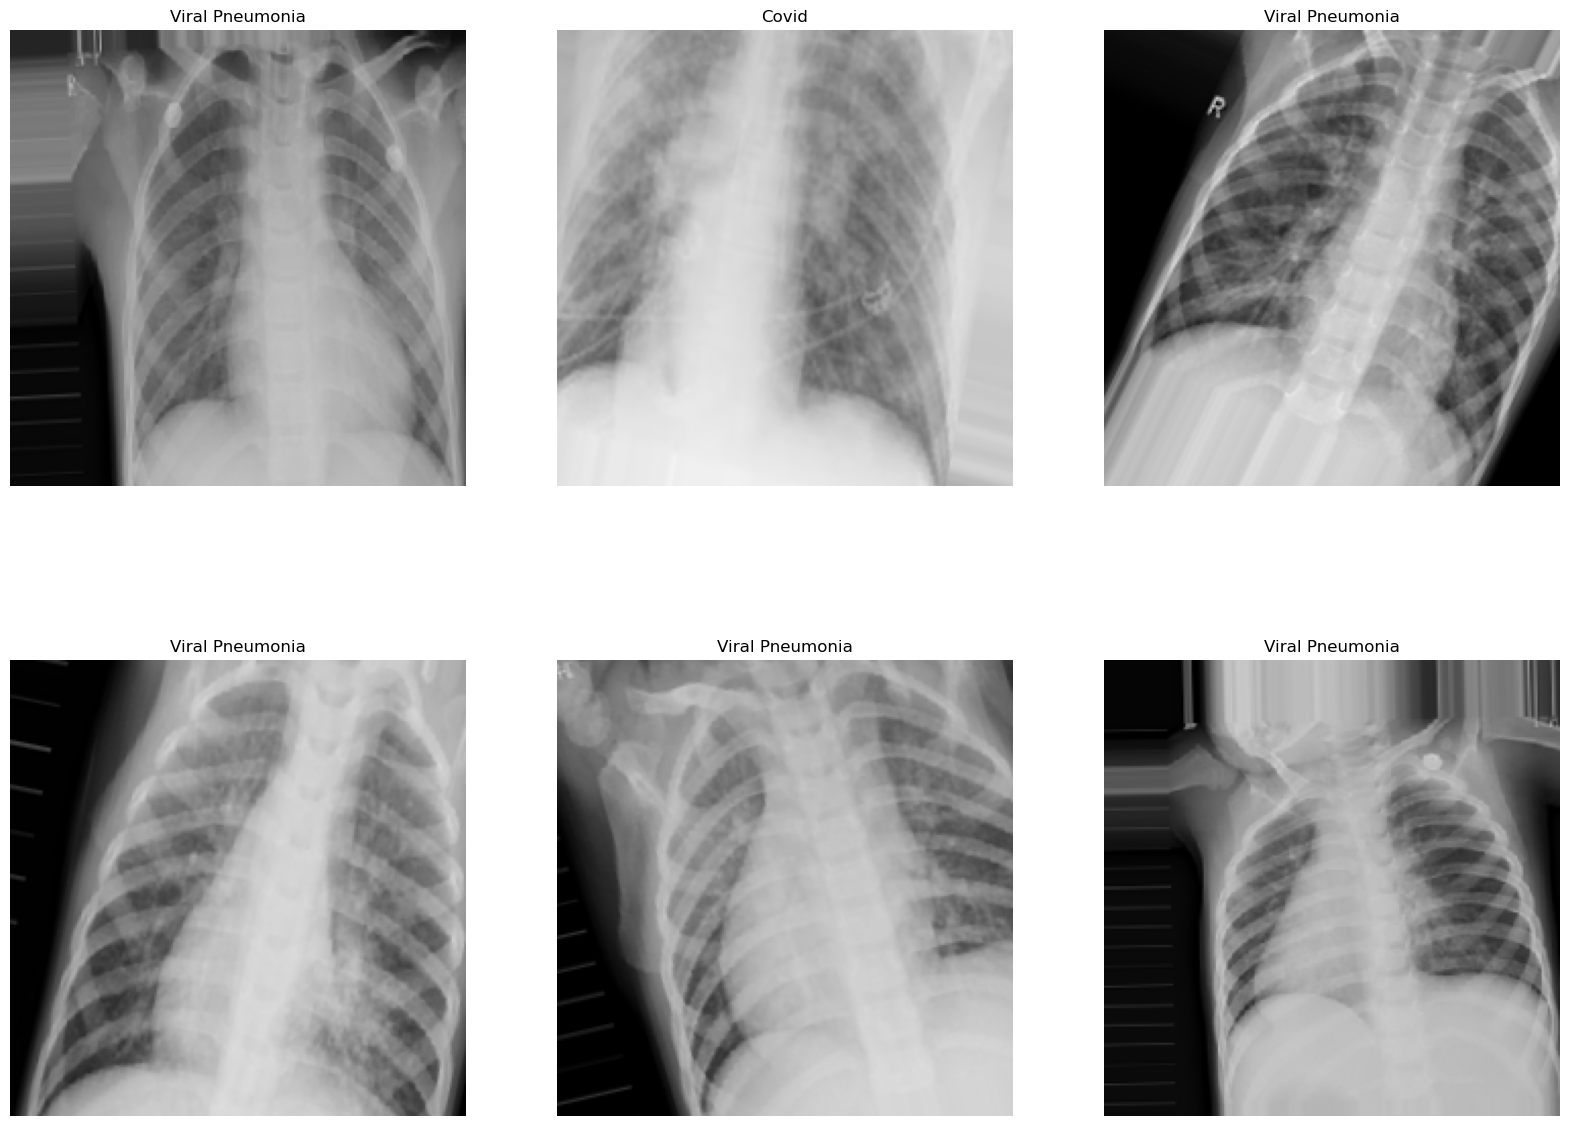

In [ ]:
def generate_data_augmented(DIR):
    datagen = ImageDataGenerator(                                              
        rescale=1./255.,                                                       
        zoom_range=0.2,         
        rotation_range=25,     
        width_shift_range=0.15,     
        height_shift_range=0.15,        
        horizontal_flip = True          
    )
    generator = datagen.flow_from_directory(
        TRAINING_DIR,                                                          
        batch_size=batch_size,                                                
        seed=42,                                                               
        class_mode='binary',                                                   
        target_size=(height, width),                                         
        classes={'Normal': 0, 'Viral Pneumonia': 1,'Covid': 2}                 
    )
    return generator

aug_train_data = generate_data_augmented(TRAINING_DIR)

image_plot(aug_train_data,6)


## Creating a sequential model to be tuned

In [16]:
tf.keras.backend.clear_session()                                               

input_shape = (height, width, 3)                                               
base_model = tf.keras.applications.vgg16.VGG16(
    weights='imagenet',                                                        
    include_top=False,                                                         
    input_shape=input_shape
)
base_model.trainable = False                                                  
tuned_ai_model = tf.keras.Sequential()                                            
tuned_ai_model.add(base_model)                                                   
tuned_ai_model.add(tf.keras.layers.GlobalAveragePooling2D())                     
tuned_ai_model.add(tf.keras.layers.Flatten())                                     
tuned_ai_model.add(tf.keras.layers.Dense(256, activation='relu'))                 
tuned_ai_model.add(tf.keras.layers.Dropout(0.5))                                 
tuned_ai_model.add(tf.keras.layers.Dense(256, activation='relu'))
tuned_ai_model.add(tf.keras.layers.Dropout(0.5))

tuned_ai_model.add(tf.keras.layers.Dense(3, activation='softmax'))            

tuned_ai_model.compile(loss='SparseCategoricalCrossentropy',                     
              optimizer=tf.keras.optimizers.Adam(0.001),                       
              metrics=['acc'])                                                 
tuned_ai_model.summary()



Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vgg16 (Functional)          (None, 7, 7, 512)         14714688  
                                                                 
 global_average_pooling2d (  (None, 512)               0         
 GlobalAveragePooling2D)                                         
                                                                 
 flatten (Flatten)           (None, 512)               0         
                                                                 
 dense (Dense)               (None, 256)               131328    
                                                                 
 dropout (Dropout)           (None, 256)               0         
                                                                 
 dense_1 (Dense)             (None, 256)               65792     
                                                       

## Training the model with the tuned pictures

In [17]:
checkpoint = tf.keras.callbacks.ModelCheckpoint('model/tuned_ai_model_best.h5', monitor='acc', verbose=1, mode='max',save_best_only=True)
early = tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min",restore_best_weights=True, patience=10)

callbacks_list = [checkpoint,early]

# training the model
history = tuned_ai_model.fit(                                                     
        aug_train_data,
        validation_data = test_data,
        epochs=50,                                                             
        shuffle=False,
        verbose=True,
        callbacks=callbacks_list
)



Epoch 1/50
11/11 [==============================] - ETA: 0s - loss: 1.2433 - acc: 0.3551
Epoch 1: acc improved from -inf to 0.35507, saving model to model\tuned_ai_model_best.h5
11/11 [==============================] - 140s 13s/step - loss: 1.2433 - acc: 0.3551 - val_loss: 1.0185 - val_acc: 0.3367
Epoch 2/50




C:\Users\taman\anaconda3\lib\site-packages\keras\src\engine\training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(




11/11 [==============================] - ETA: 0s - loss: 0.9898 - acc: 0.4870
Epoch 2: acc improved from 0.35507 to 0.48696, saving model to model\tuned_ai_model_best.h5
11/11 [==============================] - 148s 14s/step - loss: 0.9898 - acc: 0.4870 - val_loss: 0.8760 - val_acc: 0.7400
Epoch 3/50
11/11 [==============================] - ETA: 0s - loss: 0.9246 - acc: 0.5594
Epoch 3: acc improved from 0.48696 to 0.55942, saving model to model\tuned_ai_model_best.h5
11/11 [==============================] - 154s 14s/step - loss: 0.9246 - acc: 0.5594 - val_loss: 0.6830 - val_acc: 0.7833
Epoch 4/50
11/11 [==============================] - ETA: 0s - loss: 0.7833 - acc: 0.6623 
Epoch 4: acc improved from 0.55942 to 0.66232, saving model to model\tuned_ai_model_best.h5
11/11 [==============================] - 163s 15s/step - loss: 0.7833 - acc: 0.6623 - val_loss: 0.5770 - val_acc: 0.8200
Epoch 5/50
11/11 [==============================] - ETA: 0s - loss: 0.6952 - acc: 0.7174 
Epoch 5: acc 

## Evaluating the tuned model

In [18]:
ytrain = np.array([])                                                          
xtrain = []                                                                    

for i in range(math.ceil(len(aug_train_data.classes)/batch_size)):             
    xtrain.append(aug_train_data[i][0])                                        
    ytrain= np.concatenate((ytrain,aug_train_data[i][-1]))              

xtrain = np.concatenate((xtrain),axis=0)                                       

ypred_prob_train_tune = tuned_ai_model.predict(xtrain)                                        
ypred_train_tune = np.argmax(ypred_prob_train_tune,axis=1)                          



22/22 [==============================] - 93s 4s/step



## Training accuraccy

In [19]:
model_train_score = recall_score(ytrain, ypred_train_tune,average='macro')
print("Model Score on Train Data:", np.round(100*model_train_score, 2))



Model Score on Train Data: 93.36




[Text(45.72222222222221, 0.5, 'True label')]


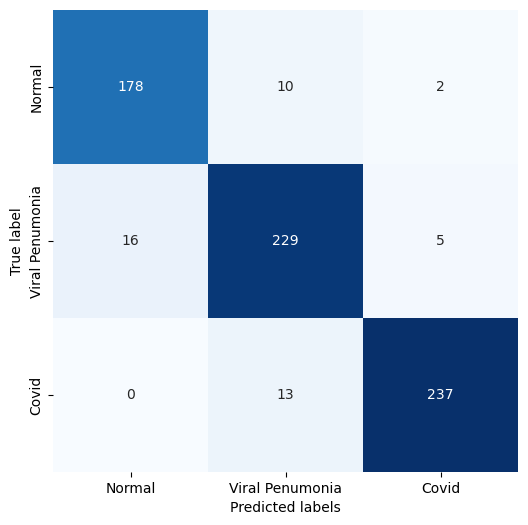

In [20]:
plt.figure(figsize=(6, 6))
hm = sns.heatmap(confusion_matrix(ytrain,ypred_train_tune), annot=True, vmin=0, fmt='g', cmap='Blues', cbar=False,xticklabels=['Normal','Viral Penumonia','Covid'],yticklabels=['Normal','Viral Penumonia','Covid'])
hm.set(xlabel='Predicted labels') 
hm.set(ylabel='True label')


## Testing the tuned model

In [21]:
ytest = np.array([])                                                           
xtest = []                                                                     

for i in range(math.ceil(len(test_data.classes)/batch_size)):                  
    xtest.append(test_data[i][0])                                          
    ytest= np.concatenate((ytest,test_data[i][-1]))                        

xtest = np.concatenate((xtest),axis=0)                                     

ypred_prob_test_tune =tuned_ai_model.predict(xtest)                                   
ypred_test_tune = np.argmax(ypred_prob_test_tune,axis=1)  



10/10 [==============================] - 38s 4s/step



In [22]:
model_test_score = recall_score(ytest, ypred_test_tune,average='macro')
print("Model Score on Test Data:", np.round(100*model_test_score, 2))



Model Score on Test Data: 94.0



## Tuned model accuraccy


[Text(45.72222222222221, 0.5, 'True label')]


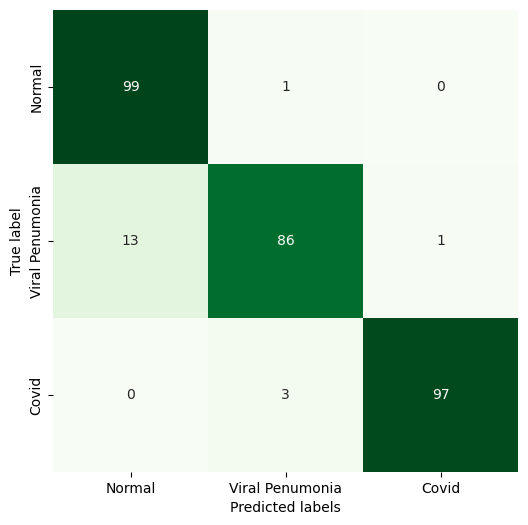

In [23]:
plt.figure(figsize=(6, 6))
hm = sns.heatmap(confusion_matrix(ytest, ypred_test_tune), annot=True, vmin=0, fmt='g', cmap='Greens', cbar=False,xticklabels=['Normal','Viral Penumonia','Covid'],yticklabels=['Normal','Viral Penumonia','Covid'])
hm.set(xlabel='Predicted labels') 
hm.set(ylabel='True label')


## The model has improved in accuracy, and I can continue onto the next step

## Saving and deploying the model

This is for general usage for less technical oriented people

In [ ]:
# path to the save the trained model
saved_model_path = "covid_detector.joblib"
joblib.dump(tuned_ai_model, saved_model_path)
covid_detector = joblib.load(saved_model_path)



['covid_detector.joblib']


In [ ]:
image = gr.Image()
label = gr.Label(num_top_classes=3)

In [ ]:
# defining the dimensions of the input image
height = 224
width = 224
dimensions = (width, height)


class_names = ['Normal','Viral Pneumonia','Covid']


def predict_covid(image):
    image = cv2.resize(image, dimensions, interpolation=cv2.INTER_LINEAR)
    image = image.reshape((-1, 224, 224, 3))
    prediction = covid_detector.predict(image).flatten()
    print(prediction)
    return {class_names[i]: float(prediction[i]) for i in range(3)}


In [13]:
# defining the structure of the deployment interface and how the components will interact
demo = gr.Interface(
    fn=predict_covid,
    inputs = image,
    outputs = label,
    title="Science Fair 2023-2024: COVID Detection",
    description= "This interface will predict whether a given patient is normal, has viral pneumonia, or has COVID based on chest X-ray scan provided.",
    allow_flagging="never"
)


In [ ]:
# deploying the model
demo.launch(inline=False, share=True, debug=True)



Running on local URL:  http://127.0.0.1:7860

Could not create share link. Missing file: C:\Users\taman\anaconda3\lib\site-packages\gradio\frpc_windows_amd64_v0.2. 

Please check your internet connection. This can happen if your antivirus software blocks the download of this file. You can install manually by following these steps: 

1. Download this file: https://cdn-media.huggingface.co/frpc-gradio-0.2/frpc_windows_amd64.exe
2. Rename the downloaded file to: frpc_windows_amd64_v0.2
3. Move the file to this location: C:\Users\taman\anaconda3\lib\site-packages\gradio
1/1 [==============================] - 1s 549ms/step
[3.244481e-24 9.761444e-34 1.000000e+00]
1/1 [==============================] - 0s 217ms/step
[6.4803507e-22 4.0775269e-38 1.0000000e+00]
1/1 [==============================] - 0s 217ms/step
[1.5365146e-36 2.8583140e-30 1.0000000e+00]
1/1 [==============================] - 0s 201ms/step
[1. 0. 0.]
1/1 [==============================] - 0s 201ms/step
[1.000000e+00 8.12746

In [ ]:
demo.close()
